# **Automated Analysis Pipeline Notebook**
## Diabetes Prediction and Automated Analysis

**Student Name:** Aeran Lee

---

**Dataset:** Pima Indians Diabetes Database (NIH–NIDDK)

**Description:** This dataset contains diagnostic measurements from women aged 21 years or older of Pima Indian heritage. The binary prediction task is to classify whether a patient has diabetes based on the available predictor variables.

**Notebook Purpose:** Demonstrate data exploration, inferential statistics, and automated machine learning workflows, including data ingestion, missing-value handling, preprocessing, model training, and evaluation.

**Note:** This dataset is used for instructional and demonstration purposes only.

In [447]:
#  @title Step 1: Data Loading

from google.colab import files
import pandas as pd
import io
from pathlib import Path

# Upload dataset
uploaded = files.upload()

# Ensure exactly one file is uploaded
if len(uploaded) != 1:
    raise ValueError("Please upload exactly one data file.")

# Identify uploaded file
filename = next(iter(uploaded))
extension = Path(filename).suffix.lower()
file_data = io.BytesIO(uploaded[filename])

# Load data based on file format
if extension in [".csv", ".tsv", ".txt"]:
    # Automatically detect the delimiter.
    df = pd.read_csv(file_data, sep=None, engine="python")

elif extension in [".xlsx", ".xls"]:
    # Load the first worksheet.
    df = pd.read_excel(file_data)

elif extension == ".json":
    df = pd.read_json(file_data)

elif extension == ".parquet":
    df = pd.read_parquet(file_data)

else:
    raise ValueError(
        f"'{extension}' files require a different reader. "
        "Supported formats: CSV, TSV, TXT, XLSX, XLS, JSON, and Parquet."
    )

# Verify successful loading
print(f"Successfully loaded: {filename}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

display(df.head())

Saving Example Dataset_Diabetes.csv to Example Dataset_Diabetes (5).csv
Successfully loaded: Example Dataset_Diabetes (5).csv
Rows: 768 | Columns: 9


,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Pipeline Modification 1: Automated and Reproducible Data Loading**

**Original approach:** The dataset was loaded using a fixed Google Drive file path, which depended on the original user's environment.

**Modification:** I replaced the fixed file path with an interactive file-upload method using files.upload(). I also implemented conditional logic (if/elif/else) to automatically select the appropriate data-loading method based on the uploaded file extension.

**Rationale:** This modification improves portability and reproducibility by allowing other users to upload the dataset without modifying a personal file path. The workflow also validates that exactly one file is uploaded, supports multiple file formats, and provides an error message for unsupported formats.

**Expected outcome:** When the cell is executed in Google Colab, users can select a dataset from their computer. The pipeline automatically loads the file into a pandas DataFrame and displays its dimensions and first five rows.


In [448]:
# @title Step 2: Data Preview (First 20 Rows)

df.head(20) # CHANGE NUMBER TO INCREASE OR DECREASE THE NUMBER OF ROWS

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [449]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/13Ccl70AFb2QftzP0mbAZL5Qm6cor3yuMqq27OZ5KXAE/edit#gid=0


In [450]:
# @title Step 3: Inspect Dataset Variables

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
attribute_list = list(df.columns)
print("Variables in the dataset:")
print("")
print(attribute_list)

Variables in the dataset:

['Pregnancies', 'Glucose', 'D_BP', 'Skin_Thickness', 'Insulin', 'BMI', 'Pedigree', 'Age', 'Outcome']


In [451]:
# @title Step 4: Check Dataset Dimensions (Rows and Columns)

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
print("Number of rows and columns:")
print("")
df.shape   # (rows, columns)

Number of rows and columns:



(768, 9)

In [452]:
# @title Step 5: Inspect Dataset Information

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Pregnancies     768 non-null    int64  
 1   Glucose         768 non-null    int64  
 2   D_BP            768 non-null    int64  
 3   Skin_Thickness  768 non-null    int64  
 4   Insulin         768 non-null    int64  
 5   BMI             768 non-null    float64
 6   Pedigree        768 non-null    float64
 7   Age             768 non-null    int64  
 8   Outcome         768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [453]:
# @title Step 6: Generate Descriptive Statistics and Variable Summary

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Describe all columns
summary = df.describe(include='all').T

# Replace NaN values with 'NA'
summary = summary.fillna('NA')

# Insert formatted variable name + data type
summary.insert(
    0,
    'Variable',
    [f"<b>{col}</b><br><span style='font-weight:normal; font-size:smaller;'>[{df[col].dtype}]</span>" for col in summary.index]
)

# Reset index to clean up formatting
summary.reset_index(drop=True, inplace=True)

# Format numeric columns to 3 decimal places only
styled_summary = (
    summary.style
    .format(precision=3, na_rep="NA")  # Format numbers to 3 decimals
    .set_table_styles([
        {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center')]}
    ])
    .hide(axis='index')  # Remove default row index
)

styled_summary

Variable,count,mean,std,min,25%,50%,75%,max
Pregnancies[int64],768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose[int64],768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
D_BP[int64],768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
Skin_Thickness[int64],768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin[int64],768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI[float64],768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
Pedigree[float64],768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age[int64],768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome[int64],768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


In [454]:
# @title Step 7: Identify and Replace Implausible Zero Values

import numpy as np

variables_to_replace_zeros = [
    'Glucose', 'D_BP', 'Skin_Thickness', 'Insulin', 'BMI'
]

# Validate required variables
missing_columns = [
    col for col in variables_to_replace_zeros
    if col not in df.columns
]

if missing_columns:
  raise ValueError(f"Missing required columns: {missing_columns}")

# Replace implausible zeros with NaN
for variable in variables_to_replace_zeros:
  zero_count = (df[variable]== 0).sum()

  df[variable] = df[variable].replace(0, np.nan)

  print(f"{variable}: {zero_count} zeros replaced with NaN")

print("\nData cleaning completed.")
print("Missing values will be imputed using training data in the ML pipeline.")

Glucose: 5 zeros replaced with NaN
D_BP: 35 zeros replaced with NaN
Skin_Thickness: 227 zeros replaced with NaN
Insulin: 374 zeros replaced with NaN
BMI: 11 zeros replaced with NaN

Data cleaning completed.
Missing values will be imputed using training data in the ML pipeline.


**Step 7:** Identify and Replace Implausible Zero Values **bold text**

**Purpose:** To identify and handle implausible zero values in the diabetes dataset before further analysis and machine learning.

In this dataset, zero values in five variables—Glucose, D_BP, Skin_Thickness, Insulin, and BMI—may represent missing or invalid measurements rather than actual physiological values.

**Data Cleaning Process:**

Verify that all five required variables exist in the dataset.

Count the number of zero values in each variable.

Replace these zero values with NaN (missing values).

Report the number of replacements for transparency and reproducibility.

**Missing Data Handling:**

Missing values will be imputed during the machine learning pipeline using training data only to prevent data leakage.

This approach preserves observations for subsequent analysis while ensuring that implausible zero values are not treated as valid measurements.

In [455]:
# @title Step 8: Automatically Identify Missing Values in Numeric Predictors

target_variable = "Outcome"

# Automatically identify numeric predictors.
numeric_predictors = df.select_dtypes(include="number").columns
numeric_predictors = numeric_predictors.drop(
    target_variable, errors="ignore"
)

# Count missing values.
missing_counts = df[numeric_predictors].isna().sum()
predictors_with_missing = missing_counts[missing_counts > 0]

# Report missing values
if predictors_with_missing.empty:
    print("No missing values detected in numeric predictors.")
else:
    print("Numeric predictors requiring imputation:")
    display(predictors_with_missing.rename("Missing values").to_frame())

    print("\nMissing values identified but not yet imputed.")
    print("Imputation will be performed using training-set medians in the ML pipeline.")

Numeric predictors requiring imputation:


,Missing values
Glucose,5
D_BP,35
Skin_Thickness,227
Insulin,374
BMI,11



Missing values identified but not yet imputed.
Imputation will be performed using training-set medians in the ML pipeline.


### Step 8: Automatically Identify Missing Values in Numeric Predictors

**Purpose:** To identify numeric predictors containing missing values before machine learning analysis.

This step automatically selects numeric variables, excludes the target variable (`Outcome`), and counts missing values in each predictor.

Conditional logic (`if/else`) determines whether missing values are present and displays the predictors requiring imputation.

Missing values are not imputed at this stage. Instead, median imputation will be performed within the machine learning pipeline using training data to prevent data leakage.

In [456]:
# @title Step 9: Generate Descriptive Statistis for a Selected Variable

# Define the variable name (this can be dynamic)
variable = 'D_BP'  # CHANGE VARIABLE HERE


#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Print the title dynamically
print(f"Quantitative Description of {variable}:")
print("")

# Get the description and round it to 3 decimal places
description = df[variable].describe().round(3)

# Print the rounded description
print(description)

Quantitative Description of D_BP:

count    733.000
mean      72.405
std       12.382
min       24.000
25%       64.000
50%       72.000
75%       80.000
max      122.000
Name: D_BP, dtype: float64


In [457]:
# @title Step 10: Summarize Non-Missing and Missing Values by Variable

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Count non-null and missing responses
response_counts = df.count()
missing_counts = df.isnull().sum()

# Combine into one DataFrame
df_count = pd.DataFrame({
    'Variable': response_counts.index,
    '# of Responses': response_counts.values,
    '# Missing': missing_counts.values
})

# Display as styled table: bold headers and center-aligned values
df_count.style.set_table_styles([
    {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]}
])

,Variable,# of Responses,# Missing
0,Pregnancies,768,0
1,Glucose,763,5
2,D_BP,733,35
3,Skin_Thickness,541,227
4,Insulin,394,374
5,BMI,757,11
6,Pedigree,768,0
7,Age,768,0
8,Outcome,768,0


In [458]:
# @title Step 11: Preview 15 Randomly Sampled Observations

df.sample(n=15, random_state=42) # CHANGE NUMBER HERE TO INCREASE OR DECREASE NUMBER OF RANDOM ROWS

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
668,6,98.0,58.0,33.0,190.0,34.0,0.430,43,0
324,2,112.0,75.0,32.0,NaN,35.7,0.148,21,0
624,2,108.0,64.0,NaN,NaN,30.8,0.158,21,0
690,8,107.0,80.0,NaN,NaN,24.6,0.856,34,0
473,7,136.0,90.0,NaN,NaN,29.9,0.210,50,0
204,6,103.0,72.0,32.0,190.0,37.7,0.324,55,0
97,1,71.0,48.0,18.0,76.0,20.4,0.323,22,0
336,0,117.0,NaN,NaN,NaN,33.8,0.932,44,0
568,4,154.0,72.0,29.0,126.0,31.3,0.338,37,0
148,5,147.0,78.0,NaN,NaN,33.7,0.218,65,0


**Pipeline Modification: Improving Reproducibility**

**Original code:** np.random.seed() followed by df.sample(n=15).

Modification: **bold text** Replaced the original code with df.sample(n=15, random_state=42).

**Rationale:** The original code did not use a fixed random seed, which could produce different samples across executions. By setting random_state=42, the same 15 observations are selected consistently, improving reproducibility and making the results easier to verify across different runs.

In [459]:
# @title Step 12: Convert and Verify Variable Data Types

# Choose variable to change
variable_to_change = 'Outcome' # CHANGE THIS VARIABLE
new_data_type = 'category' # CHANGE THIS TO THE NEW DATA TYPE (options include category, int64, float)

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
# Capture original data type
original_dtype = df[variable_to_change].dtype

# Change data type (options include category, float, int64)
df[variable_to_change] = df[variable_to_change].astype(new_data_type)

# Capture new data type
new_dtype = df[variable_to_change].dtype

# Print result dynamically
print(f"'{variable_to_change}' variable changed from {original_dtype} to {new_dtype}")
print("")
print("Note: You can revise the code to change the data type for a different variable.")

'Outcome' variable changed from int64 to category

Note: You can revise the code to change the data type for a different variable.


**Step 12:** **Convert and Verify Variable Data Types**

**Purpose:** To ensure that variables are represented using appropriate data types for subsequent statistical analysis and machine learning.

This step allows users to select a variable and convert its data type. In this example, Outcome is converted from an integer to a categorical variable because it represents binary diabetes status (0 = non-diabetic, 1 = diabetic).

The code automatically displays the original and updated data types, allowing users to verify the conversion.

This improves the flexibility of the analytical workflow by allowing data types to be adjusted according to the characteristics of the selected variable.

## **Exploratory Data Analysis**

In [460]:
# @title Step 13: Pearson's Correaltion

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.corr()

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
Pregnancies,1.000000,0.128135,0.214178,0.100239,0.082171,0.021719,-0.033523,0.544341,0.221898
Glucose,0.128135,1.000000,0.223192,0.228043,0.581186,0.232771,0.137246,0.267136,0.494650
D_BP,0.214178,0.223192,1.000000,0.226839,0.098272,0.289230,-0.002805,0.330107,0.170589
Skin_Thickness,0.100239,0.228043,0.226839,1.000000,0.184888,0.648214,0.115016,0.166816,0.259491
Insulin,0.082171,0.581186,0.098272,0.184888,1.000000,0.228050,0.130395,0.220261,0.303454
BMI,0.021719,0.232771,0.289230,0.648214,0.228050,1.000000,0.155382,0.025841,0.313680
Pedigree,-0.033523,0.137246,-0.002805,0.115016,0.130395,0.155382,1.000000,0.033561,0.173844
Age,0.544341,0.267136,0.330107,0.166816,0.220261,0.025841,0.033561,1.000000,0.238356
Outcome,0.221898,0.494650,0.170589,0.259491,0.303454,0.313680,0.173844,0.238356,1.000000


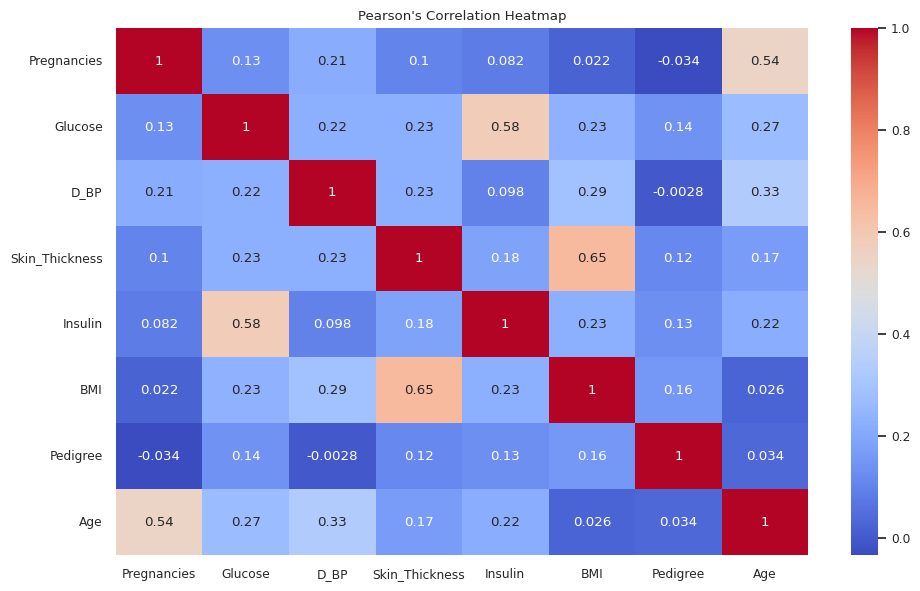

In [461]:
# @title Step 14: Pearson's correlation heatmap

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.set(font_scale=0.8)

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Pearson's Correlation Heatmap")
plt.tight_layout()
plt.show()

In [462]:
# @title Step 15: Spearman's Rank correlation table

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.corr(method='spearman')

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
Pregnancies,1.000000,0.129547,0.194103,0.086734,0.127859,0.000279,-0.043242,0.607216,0.198689
Glucose,0.129547,1.000000,0.249415,0.229815,0.658813,0.227761,0.090596,0.283315,0.483364
D_BP,0.194103,0.249415,1.000000,0.248017,0.130463,0.299176,0.008511,0.370609,0.177227
Skin_Thickness,0.086734,0.229815,0.248017,1.000000,0.245188,0.685380,0.074979,0.231132,0.265397
Insulin,0.127859,0.658813,0.130463,0.245188,1.000000,0.303515,0.130262,0.267437,0.377300
BMI,0.000279,0.227761,0.299176,0.685380,0.303515,1.000000,0.136138,0.121119,0.309324
Pedigree,-0.043242,0.090596,0.008511,0.074979,0.130262,0.136138,1.000000,0.042909,0.175353
Age,0.607216,0.283315,0.370609,0.231132,0.267437,0.121119,0.042909,1.000000,0.309040
Outcome,0.198689,0.483364,0.177227,0.265397,0.377300,0.309324,0.175353,0.309040,1.000000


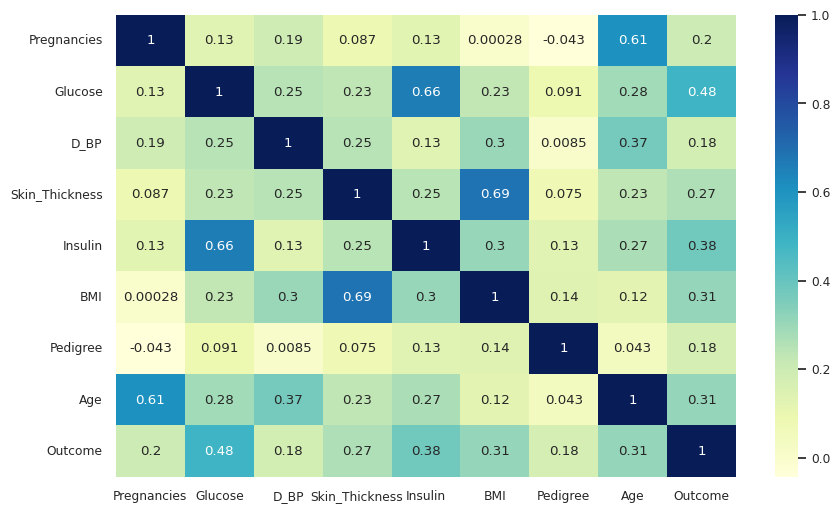

In [463]:
# @title Step 16: Spearman's Rank correlation heatmap

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
plt.figure(figsize=(10,6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5
sns.heatmap(df.corr(method='spearman'), annot=True, cmap="YlGnBu");

In [464]:
# @title Step 16-A: Identify Strong Correaltion Using a User-Defined Threshold with parameter 0.5

# Analytical parameter
correlation_threshold = 0.50

# Calculate Spearman Correaltion
corr_matrix = df.corr(method="spearman", numeric_only=True)

# Identify correalations above the threshold
strong_correlations = []

for i, var1 in enumerate(corr_matrix.columns):
  for var2 in corr_matrix.columns[i + 1:]:
    correlation = corr_matrix.loc[var1, var2]

    if abs(correlation) >= correlation_threshold:
      strong_correlations.append({
          "Variable 1": var1,
          "Variable 2": var2,
          "Spearman Correlation": round(correlation, 3)
      })

# Display results
if strong_correlations:
    results = pd.DataFrame(strong_correlations)
    display(results)
else:
  print("No correlations meet the selected threshold")

,Variable 1,Variable 2,Spearman Correlation
0,Pregnancies,Age,0.607
1,Glucose,Insulin,0.659
2,Skin_Thickness,BMI,0.685


In [465]:
# @title Step 16-B: Identify Strong Correaltion Using a User-Defined Threshold with parameter 0.3

# Analytical parameter
correlation_threshold = 0.30

# Calculate Spearman Correaltion
corr_matrix = df.corr(method="spearman", numeric_only=True)

# Identify correalations above the threshold
strong_correlations = []

for i, var1 in enumerate(corr_matrix.columns):
  for var2 in corr_matrix.columns[i + 1:]:
    correlation = corr_matrix.loc[var1, var2]

    if abs(correlation) >= correlation_threshold:
      strong_correlations.append({
          "Variable 1": var1,
          "Variable 2": var2,
          "Spearman Correlation": round(correlation, 3)
      })

# Display results
if strong_correlations:
    results = pd.DataFrame(strong_correlations)
    display(results)
else:
  print("No correlations meet the selected threshold")

,Variable 1,Variable 2,Spearman Correlation
0,Pregnancies,Age,0.607
1,Glucose,Insulin,0.659
2,D_BP,Age,0.371
3,Skin_Thickness,BMI,0.685
4,Insulin,BMI,0.304


Step 16-C: Pipeline Modification 2: Adjusting the Correlation Threshold

**Original approach:** The pipeline displayed correlation matrices without applying a user-defined threshold to identify stronger relationships.

**Modification:** I added a configurable correlation threshold to automatically identify variable pairs with Spearman correlation coefficients above a selected absolute value. I compared thresholds of 0.50 and 0.30.

**Rationale:** Adjusting the threshold allows users to control which relationships are highlighted based on their analytical goals. A higher threshold identifies fewer, stronger associations, while a lower threshold includes more potentially relevant relationships.

**Conditional logic:** The pipeline uses `if` statements to determine which variable pairs meet the selected threshold and whether any qualifying relationships should be displayed.

**Interpretation:** Changing the threshold affects which relationships are reported, but it does not change the underlying correlation coefficients.

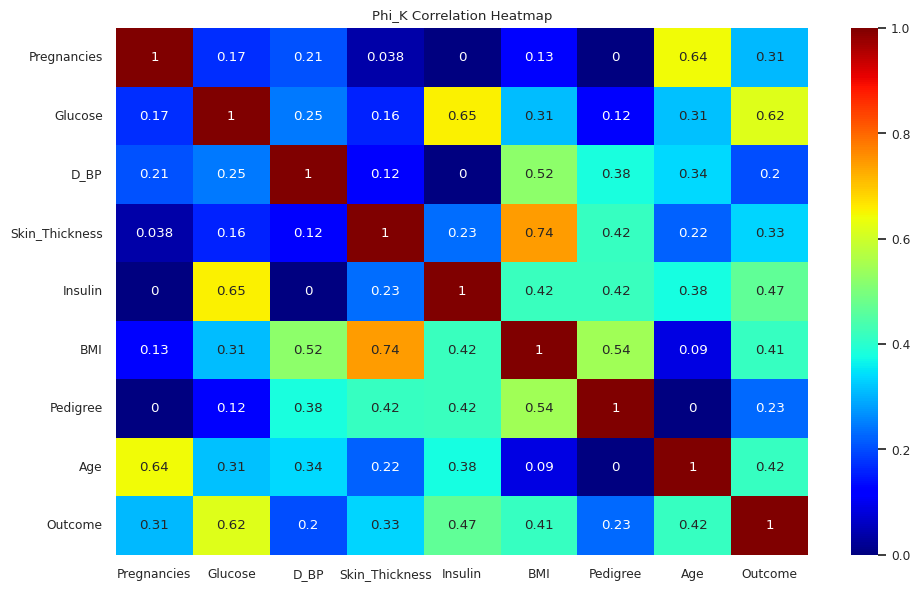

In [466]:
# @title Step 17: Phi-K correlation heatmap

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

import os
import sys
import subprocess

# Suppress pip install output
subprocess.run([sys.executable, "-m", "pip", "install", "phik"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import phik
from phik import resources, report
from phik.report import plot_correlation_matrix
from phik import phik_matrix

# Identify interval (numerical) columns
interval_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Create correlation map using Phi-K
plt.figure(figsize=(10, 6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

# Compute and plot Phi-K correlation matrix with interval columns specified
phik_corr = df.phik_matrix(interval_cols=interval_cols)
sns.heatmap(phik_corr, annot=True, cmap="jet")

plt.title("Phi_K Correlation Heatmap")
plt.tight_layout()
plt.show()

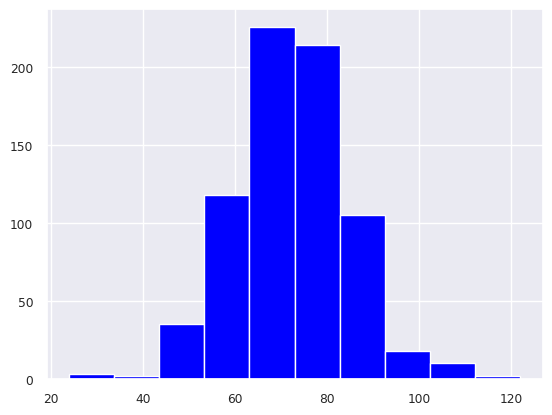

In [467]:
# @title Step 18: Example of a histogram
plt.hist(df['D_BP'], color='blue'); # CHANGE VARIABLE HERE

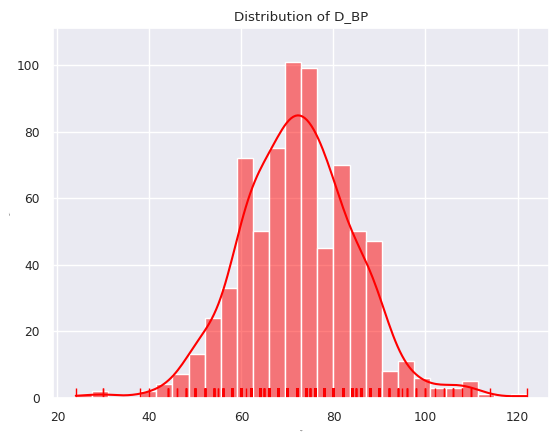

In [468]:
# @title Step 19: Example of a distribution plot

import seaborn as sns
import matplotlib.pyplot as plt

variable = "D_BP"

sns.histplot(data=df, x=variable, color="red", kde=True)
sns.rugplot(data=df, x=variable, color="red")

plt.title(f"Distribution of {variable}")
plt.show()

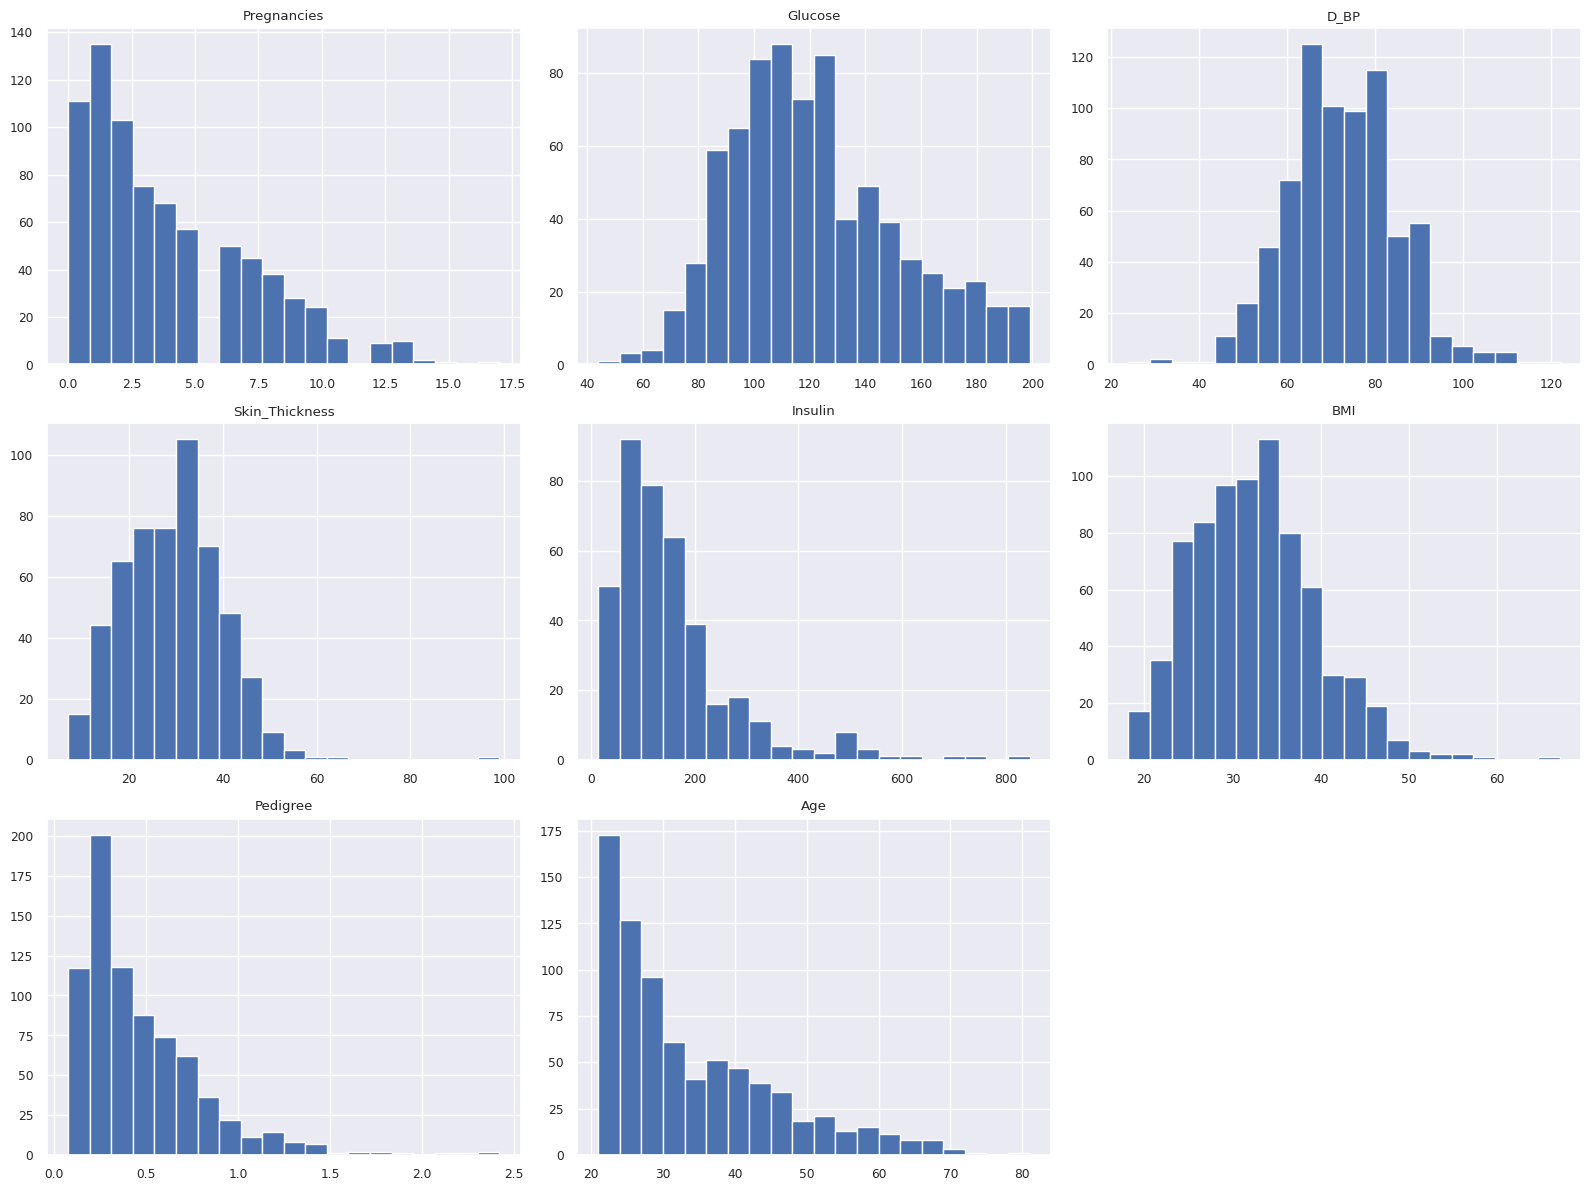

In [469]:
# @title Step 20: Generate histograms for all numerical variables
df.hist(figsize=(16,12), bins=20)
plt.tight_layout()
plt.show()

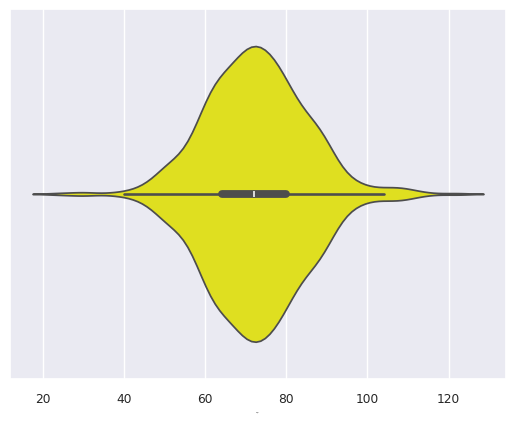

In [470]:
# @title Step 21: Example of a violin plot
sns.violinplot(df['D_BP'], color='yellow', orient='h'); # CHANGE VARIABLE AND COLOR HERE

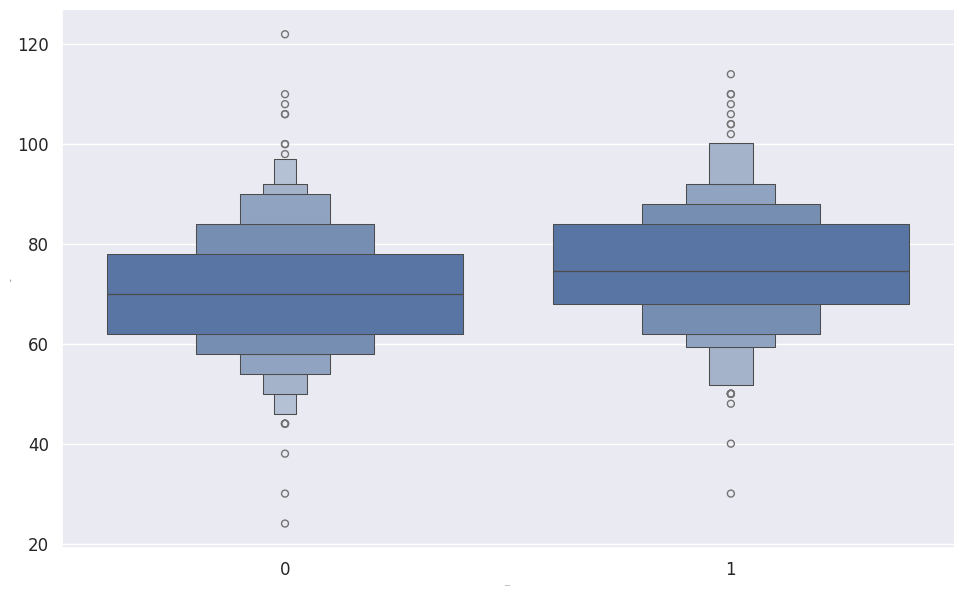

In [471]:
# @title Step 22: Example of categorical plot
# Define the plot variables
x_var = "Outcome"
y_var = "D_BP"

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Create the plot
g = sns.catplot(x=x_var, y=y_var, data=df, kind='boxen', height=6, aspect=1.6, estimator=np.mean);

# Dynamically set axis labels
g.set_axis_labels(x_var, y_var)
g.set_titles("{col_name}")

# Optionally set font size
g.set(xlabel=x_var, ylabel=y_var)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [472]:
# @title Step 23: Define a function to create a boxplot and histogram combo

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
def histogram_boxplot(feature, figsize=(10,6), bins=None):
    """ Boxplot and histogram combined (horizontal boxplot version)
    feature: 1-d feature array
    figsize: size of fig (default (10,6))
    bins: number of bins (default None / auto)
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    from scipy.stats import norm

    sns.set(font_scale=1)
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (.25, .75)},
        figsize=figsize
    )

    # Horizontal boxplot
    sns.boxplot(x=feature, ax=ax_box2, showmeans=True, color='red')

    # Histogram
    if bins:
        sns.histplot(feature, kde=False, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(feature, kde=False, ax=ax_hist2)

    # Add central tendency lines to histogram
    ax_hist2.axvline(np.mean(feature), color='black', linestyle='--', label='Mean')
    ax_hist2.axvline(np.median(feature), color='green', linestyle='-', label='Median')
    ax_hist2.axvline(feature.mode()[0], color='red', linestyle='dashed', linewidth=1, label='Mode')

    ax_hist2.legend()
    plt.tight_layout()
    plt.show()

print("Function successfully created")

Function successfully created


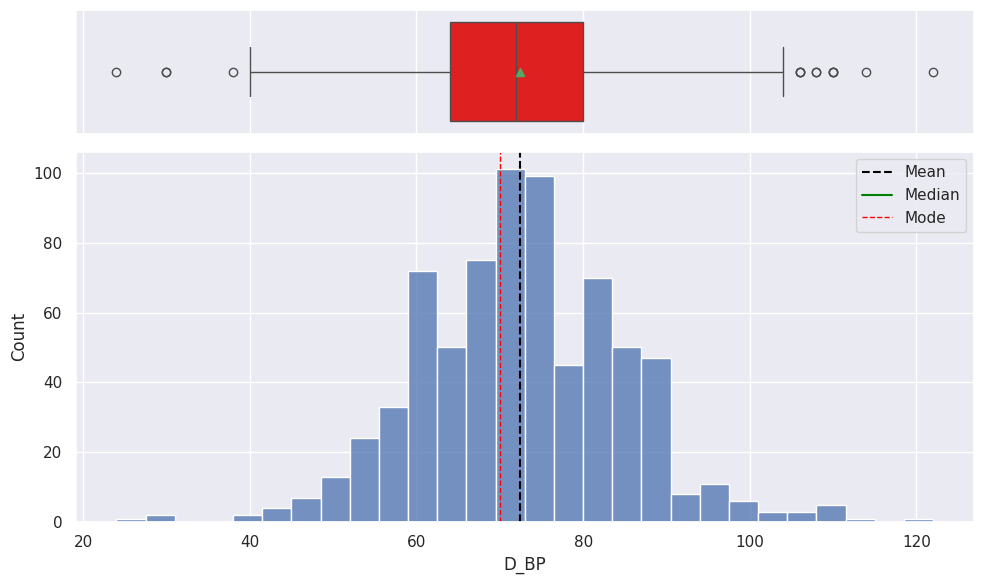

In [473]:
# @title Step 24: Example of a combination boxplot and histogram

histogram_boxplot(df.D_BP) # CHANGE THE CONTINUOUS VARIABLE HERE

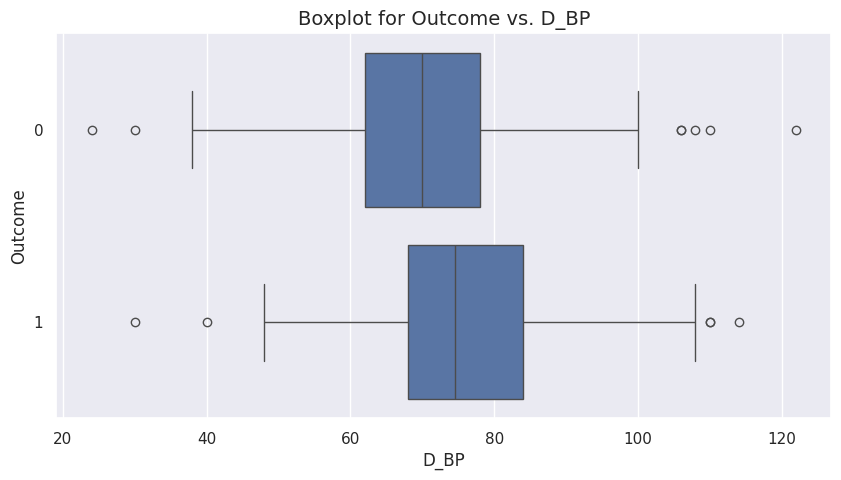

In [474]:
# @title Step 25: Example of boxplot with the primary outcome and a continuous variable

# Define variables
x_var = "D_BP" # CHANGE VARIABLE HERE
y_var = "Outcome"  # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Plot
plt.figure(figsize=(10, 5))
sns.boxplot(x=x_var, y=y_var, data=df)

# Dynamic labels and title
plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'Boxplot for {y_var} vs. {x_var}', fontsize=14)

plt.show()

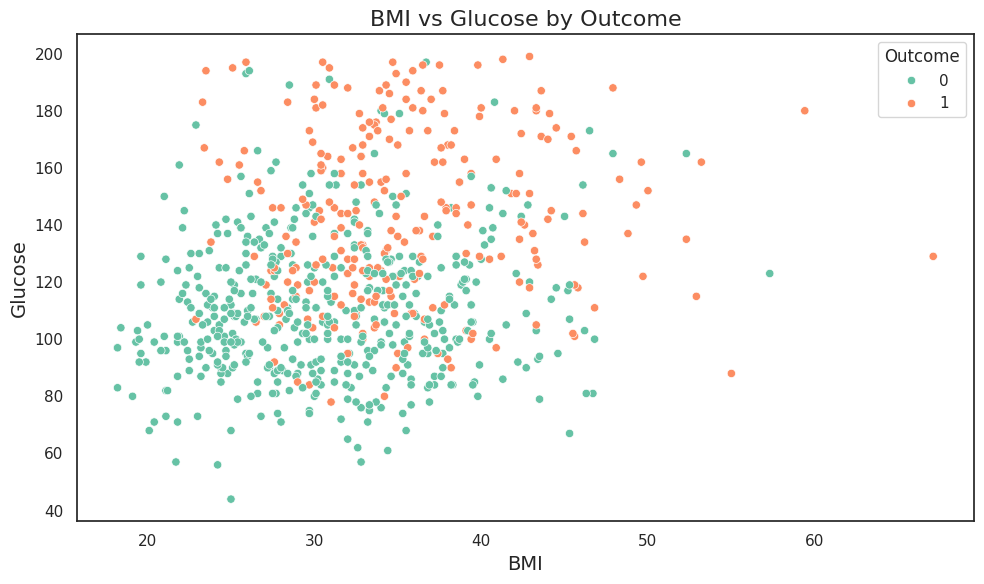

In [475]:
# @title Step 26: Example of a scatterplot

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Create the scatterplot
sns.set(style="white")  # Clean background without gridlines
plt.figure(figsize=(10, 6))

# Scatterplot
sns.scatterplot(x='BMI', y='Glucose', hue='Outcome', data=df, palette='Set2')

# Add title and axis labels
plt.title('BMI vs Glucose by Outcome', fontsize=16)
plt.xlabel('BMI', fontsize=14)
plt.ylabel('Glucose', fontsize=14)

# Remove gridlines
plt.grid(False)

# Adjust layout to prevent labels from being cut off
plt.tight_layout()

# Show the plot
plt.show()

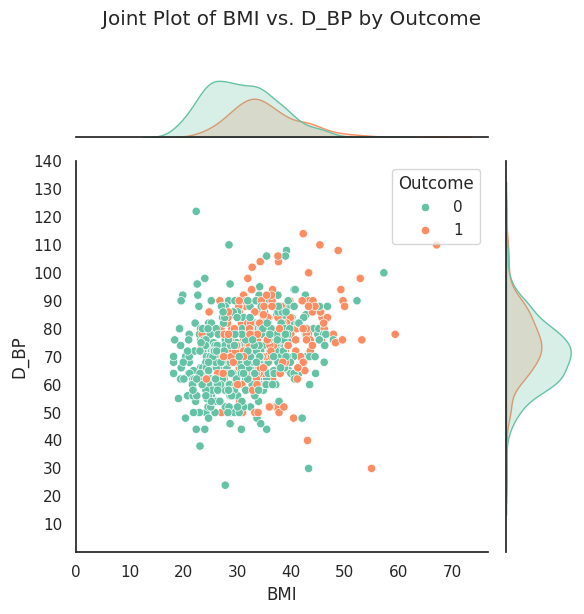

In [476]:
# @title Step 27: Example of a joint plot (3 variables)
g = sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='D_BP', # CHANGE VARIABLE HERE
    hue='Outcome',
    data=df,
    palette='Set2',
    height=6,
)

# Set x-axis and y-axis limits
g.ax_joint.set_xlim(left=0)
g.ax_joint.set_ylim(bottom=0)

# Set y-axis ticks to increase by 10
y_min, y_max = g.ax_joint.get_ylim()
g.ax_joint.set_yticks(np.arange(10, y_max + 10, 10))

# Add title
plt.suptitle("Joint Plot of BMI vs. D_BP by Outcome", y=1.02)
plt.tight_layout()
plt.show()

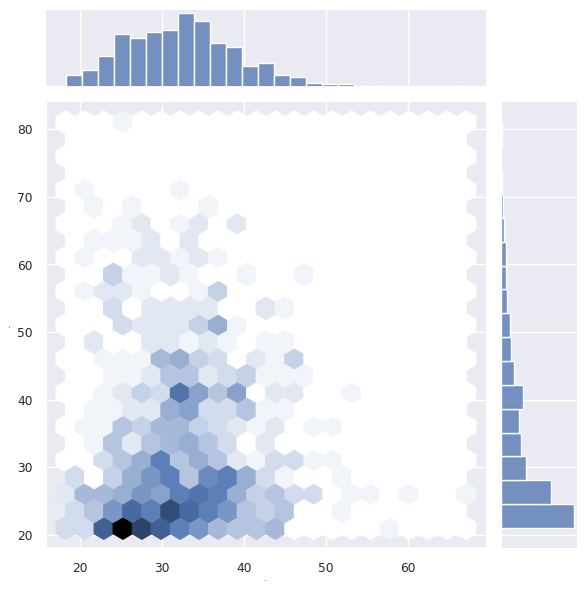

In [477]:
# @title Step 28: Example of a joint plot of a different kind (2 variables)

sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='Age', # CHANGE VARIABLE HERE #---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
    kind='hex',
    data=df,
    palette='Set2',
    height=6  # Smaller and more compact
);

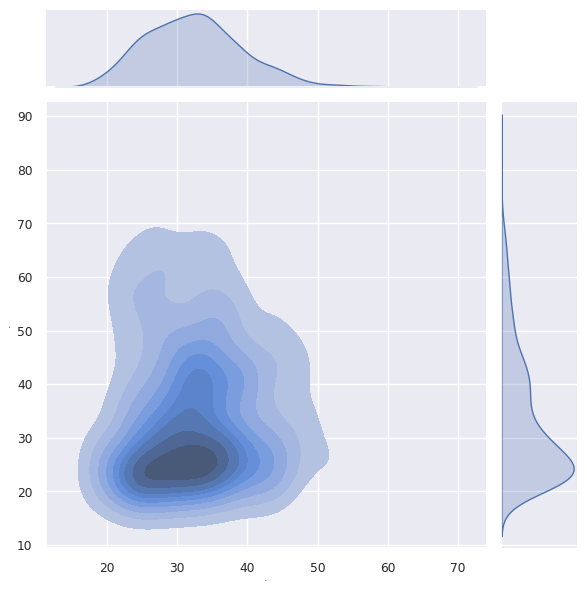

In [478]:
# @title Step 29: Another example of a joint plot of a different kind (2 variables)
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='Age', # CHANGE VARIABLE HERE #---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
    kind='kde',
    fill = True,
    data=df,
    palette='Set2',
    height=6  # Smaller and more compact
);

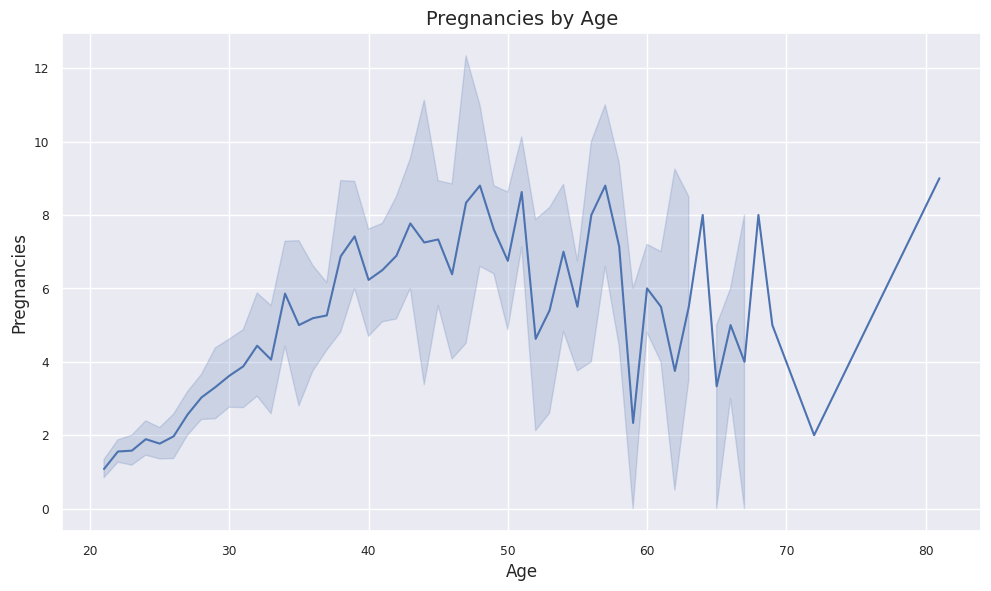

In [479]:
# @title Step 30: Example of a line plot

# Define x and y columns
x_col = 'Age' # CHANGE VARIABLE HERE
y_col = 'Pregnancies' # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Set up figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Create lineplot
sns.lineplot(x=x_col, y=y_col, data=df, ax=ax)

# Set axis labels and title explicitly
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.set_title(f'{y_col} by {x_col}', fontsize=14)

# Ensure labels are not cut off
plt.tight_layout()

# Show the plot
plt.show()

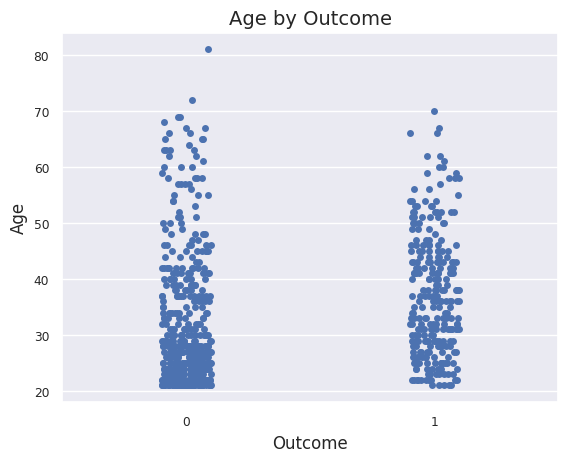

In [480]:
# @title Step 31: Example of a strip plot

# Define axis variables
x_var = "Outcome"  # CHANGE VARIABLE HERE
y_var = "Age"      # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
sns.stripplot(data=df, x=x_var, y=y_var, jitter=True)
plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'{y_var} by {x_var}', fontsize=14)
plt.show()

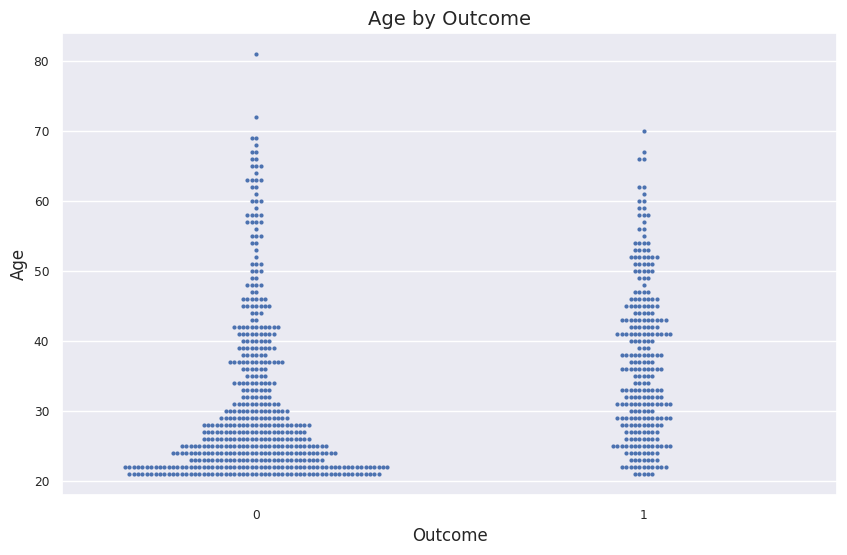

In [481]:
# @title Step 32: Example of a swarm plot

x_var = "Outcome"
y_var = "Age"

plt.figure(figsize=(10, 6))
sns.swarmplot(data=df, x=x_var, y=y_var, size=3)

plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'{y_var} by {x_var}', fontsize=14)
plt.show()

**Link to other data visualizations: https://seaborn.pydata.org/examples/index.html**

## **Inferential Statistics**

In [482]:
# @title **Import additional inferential statistics libraries**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
import math
from scipy.stats import ttest_1samp
from scipy.stats import ttest_ind

print("Libraries successfully imported.")

Libraries successfully imported.


In [483]:
# @title Step 33: Example of a one-sample t-test

from scipy.stats import ttest_1samp

variable = "BMI"       # CHANGE VARIABLE HERE
threshold = 30        # CHANGE REFERENCE VALUE HERE
alpha = 0.05          # CHANGE SIGNIFICANCE LEVEL HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude missing observations.
values = df[variable].dropna()

if len(values) < 2 or values.std() == 0:
    raise ValueError(
        "The test requires at least two nonmissing values and nonzero variance."
    )

# Perform a two-sided one-sample t-test.
t_statistic, p_value = ttest_1samp(values, popmean=threshold)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    direction = "higher" if t_statistic > 0 else "lower"
    interpretation = (
        f"There is evidence that the population mean {variable} "
        f"is {direction} than {threshold}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence that the population mean "
        f"{variable} differs from {threshold}."
    )

print(f"Null hypothesis: The population mean {variable} equals {threshold}.")
print(f"Alternative hypothesis: The population mean {variable} differs from {threshold}.")
print(f"\nNonmissing observations: {len(values)}")
print(f"Sample mean: {values.mean():.3f}")
print(f"t-statistic: {t_statistic:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: The population mean BMI equals 30.
Alternative hypothesis: The population mean BMI differs from 30.

Nonmissing observations: 757
Sample mean: 32.457
t-statistic: 9.764
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that the population mean BMI is higher than 30.


In [484]:
# @title Step 34: Independent samples t-test (specific to this dataset)

from scipy.stats import ttest_ind

variable = "BMI"
group_col = "Outcome"
alpha = 0.05

label_map = {0: "Patients without diabetes", 1: "Patients with diabetes"}

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude observations missing either the measurement or group.
test_data = df[[variable, group_col]].dropna()

if set(test_data[group_col].unique()) != {0, 1}:
    raise ValueError("The group variable must contain both groups, coded 0 and 1.")

# Set a consistent comparison order.
group1 = test_data.loc[test_data[group_col] == 0, variable]
group2 = test_data.loc[test_data[group_col] == 1, variable]

if len(group1) < 2 or len(group2) < 2:
    raise ValueError("Each group requires at least two nonmissing observations.")

if group1.var() == 0 and group2.var() == 0:
    raise ValueError("The test requires variation in at least one group.")

group1_name = label_map[0]
group2_name = label_map[1]

# Two-sided Welch's t-test.
t_statistic, p_value = ttest_ind(group1, group2, equal_var=False)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    direction = "higher" if t_statistic > 0 else "lower"
    interpretation = (
        f"There is evidence that the population mean {variable} "
        f"for {group1_name.lower()} is {direction} than "
        f"for {group2_name.lower()}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence of a difference in population "
        f"mean {variable} between the two groups."
    )

print(f"Null hypothesis: The population mean {variable} is equal between groups.")
print(f"Alternative hypothesis: The population mean {variable} differs between groups.")

print(f"\n{group1_name}: n = {len(group1)}, mean = {group1.mean():.3f}")
print(f"{group2_name}: n = {len(group2)}, mean = {group2.mean():.3f}")
print(f"Mean difference (group 0 − group 1): {group1.mean() - group2.mean():.3f}")

print(f"\nWelch's independent samples t-test:")
print(f"t-statistic: {t_statistic:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: The population mean BMI is equal between groups.
Alternative hypothesis: The population mean BMI differs between groups.

Patients without diabetes: n = 491, mean = 30.860
Patients with diabetes: n = 266, mean = 35.407
Mean difference (group 0 − group 1): -4.547

Welch's independent samples t-test:
t-statistic: -9.055
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that the population mean BMI for patients without diabetes is lower than for patients with diabetes.


In [485]:
# @title Step 35: One-way ANOVA (specific to this dataset)

import statsmodels.api as sm
from statsmodels.formula.api import ols

variable = "Glucose"
group_col = "Outcome"
alpha = 0.05

label_map = {
    0: "Patients without diabetes",
    1: "Patients with diabetes"
}

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude observations missing the measurement or group.
test_data = df[[variable, group_col]].dropna().copy()

# Use standard column names for the model formula.
test_data.columns = ["measurement", "group"]
test_data["group"] = test_data["group"].astype("category")
test_data["group"] = test_data["group"].cat.remove_unused_categories()

group_summary = (
    test_data.groupby("group", observed=True)["measurement"]
    .agg(["count", "mean", "std"])
)

if len(group_summary) < 2:
    raise ValueError("ANOVA requires at least two groups.")

if (group_summary["count"] < 2).any():
    raise ValueError("Each group requires at least two nonmissing observations.")

if (group_summary["std"] == 0).all():
    raise ValueError("The test requires variation within at least one group.")

# Fit the model and calculate the ANOVA table.
anova_model = ols("measurement ~ C(group)", data=test_data).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)

f_stat = anova_table.loc["C(group)", "F"]
p_value = anova_table.loc["C(group)", "PR(>F)"]

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    interpretation = (
        f"There is evidence that at least two groups differ "
        f"in population mean {variable}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence of a difference "
        f"in population mean {variable} across groups."
    )

# Apply readable group labels for display.
group_summary.index = [
    label_map.get(group, str(group))
    for group in group_summary.index
]

print(f"Null hypothesis: Population mean {variable} is equal across all groups.")
print(f"Alternative hypothesis: At least one population mean differs.")

print("\nGroup summaries:")
display(group_summary.round(3))

print("\nANOVA table:")
display(anova_table.round(3))

print(f"\nF-statistic: {f_stat:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: Population mean Glucose is equal across all groups.
Alternative hypothesis: At least one population mean differs.

Group summaries:


,count,mean,std
Patients without diabetes,497,110.644,24.777
Patients with diabetes,266,142.320,29.599



ANOVA table:


,sum_sq,df,F,PR(>F)
C(group),173846.334,1.0,246.518,0.0
Residual,536661.802,761.0,NaN,NaN



F-statistic: 246.518
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that at least two groups differ in population mean Glucose.


In [486]:
# @title Step 36: Chi-square test of independence (specific to this dataset)

import pandas as pd
from scipy.stats import chi2_contingency

group_col = "Outcome"
variable = "Pregnancies"
threshold = 10
alpha = 0.05

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude missing values before creating categories.
test_data = df[[group_col, variable]].dropna().copy()
test_data["Above threshold"] = test_data[variable] > threshold

crosstab = pd.crosstab(
    test_data[group_col],
    test_data["Above threshold"]
)

if crosstab.shape[0] < 2 or crosstab.shape[1] < 2:
    raise ValueError("The test requires at least two observed categories per variable.")

# Run Pearson's chi-square test without continuity correction.
chi2_stat, p_value, dof, expected = chi2_contingency(
    crosstab, correction=False
)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

print("Observed counts (False = ≤ threshold; True = > threshold):")
display(crosstab)

print("\nExpected counts under independence:")
display(pd.DataFrame(
    expected,
    index=crosstab.index,
    columns=crosstab.columns
).round(3))

print(f"\nNull hypothesis: {group_col} and {variable} > {threshold} are independent.")
print(f"Chi-square statistic: {chi2_stat:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p {formatted_p}")

if (expected < 5).any():
    print(
        "\nSmall expected counts detected. For this 2×2 table, "
        "consider Fisher's exact test before interpreting the chi-square result."
    )

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print(
        f"Interpretation: There is evidence of an association between "
        f"{group_col} and having {variable} > {threshold}, "
        "provided the test assumptions are met."
    )
else:
    print("Decision: Fail to reject the null hypothesis.")
    print(
        f"Interpretation: There is insufficient evidence of an association "
        f"between {group_col} and having {variable} > {threshold}, "
        "provided the test assumptions are met."
    )

Observed counts (False = ≤ threshold; True = > threshold):


Above threshold,False,True
Outcome,,
0,486,14
1,248,20



Expected counts under independence:


Above threshold,False,True
Outcome,,
0,477.865,22.135
1,256.135,11.865



Null hypothesis: Outcome and Pregnancies > 10 are independent.
Chi-square statistic: 8.965
Degrees of freedom: 1
p = 0.003
Decision: Reject the null hypothesis.
Interpretation: There is evidence of an association between Outcome and having Pregnancies > 10, provided the test assumptions are met.


In [487]:
# @title Step 37: Encode outcome labels as 0 and 1 (if needed)

target_variable = "Outcome"
label_map = {"No Diabetes": 0, "Diabetes": 1}

outcome = df[target_variable]
observed_values = set(outcome.dropna().unique())

if observed_values.issubset({0, 1}):
    print("Outcome is already coded as 0/1.")

elif observed_values.issubset(set(label_map)):
    df[target_variable] = outcome.map(label_map)
    print("Outcome labels converted to 0/1.")

else:
    raise ValueError(
        f"Unexpected outcome values: {observed_values}. "
        "Update label_map to match your dataset."
    )

display(df[target_variable].head(10))

Outcome is already coded as 0/1.


,Outcome
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1
9,1


## **Supervised Machine Learning (Binary Classification)**

**Two examples:**
- Logistic Regression  
- Decision Tree  

**LOGISTIC REGRESSION:** Additional Info on Logistic Regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

## **Logistic Regression**

In [488]:
# @title Step 38: Configure and split data for the automated ML pipeline

from sklearn.model_selection import train_test_split

target_variable = "Outcome"  # CHANGE FOR YOUR DATASET

# Exclude rows with missing outcomes; do not impute the outcome.
ml_data = df.dropna(subset=[target_variable]).copy()

X = ml_data.drop(columns=[target_variable])
y = ml_data[target_variable]

# This demonstration expects numeric predictors and an outcome coded 0/1.
if set(y.unique()) != {0, 1}:
    raise ValueError("The outcome must contain both classes, coded 0 and 1.")

if not all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns):
    raise ValueError("This pipeline requires numeric predictors.")

y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 537
Test observations: 231


Step 38: Data Preparation and Train-Test Split

The dataset was prepared for binary classification using Outcome as the target variable (0 = non-diabetic, 1 = diabetic). Rows with missing outcome values were excluded, and the remaining variables were used as predictors. The dataset was split into 70% training data (n = 537) and 30% testing data (n = 231). Stratified sampling was applied to preserve the proportion of diabetic and non-diabetic patients in both sets. A fixed random state (random_state=42) was used to ensure reproducibility. The training set will be used to develop the logistic regression model, while the test set will evaluate its performance on unseen data.

In [489]:
# @title Step 39: Define a function to display a confusion matrix

from sklearn.metrics import confusion_matrix

def make_confusion_matrix(y_actual, y_predict):
    """Display counts and percentages of all evaluated observations."""

    cm = confusion_matrix(y_actual, y_predict, labels=[0, 1])

    if cm.sum() == 0:
        raise ValueError("No observations with labels 0 or 1 to display.")

    cell_names = np.array([
        ["True negative", "False positive"],
        ["False negative", "True positive"]
    ])

    annotations = np.array([
        f"{name}\n{count}\n{count / cm.sum():.2%}"
        for name, count in zip(cell_names.flatten(), cm.flatten())
    ]).reshape(2, 2)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=annotations,
        fmt="",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

print("Function successfully created.")

Function successfully created.


### Step 39: Confusion Matrix Function

A confusion matrix function was created to evaluate the performance of the binary classification model by comparing actual and predicted outcomes. The function calculates True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN), displaying both counts and percentages in a heatmap. It also includes a validation check to prevent displaying an empty confusion matrix. The function was successfully defined and will be used to evaluate the logistic regression model after predictions are generated.

In [490]:
# @title Step 40: Build logistic regression with automated preprocessing

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Learn imputation and scaling from training data only.
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        solver="liblinear",
        random_state=42
    ))
])

logistic_pipeline.fit(X_train, y_train)

# Apply the fitted preprocessing and model to test data.
y_predict = logistic_pipeline.predict(X_test)
model_score = logistic_pipeline.score(X_test, y_test)

print(f"Test-set accuracy: {model_score:.2%}")
print(
    f"The model correctly classified {model_score:.2%} "
    "of observations in the test set."
)

Test-set accuracy: 74.46%
The model correctly classified 74.46% of observations in the test set.


Step 40: Logistic Regression Model and Performance

A logistic regression model was developed using an automated preprocessing pipeline that included median imputation for missing values and standardization of predictor variables. The model was trained on the training dataset and evaluated using the test dataset (n = 231). The model achieved a test-set accuracy of 74.46%, indicating that it correctly classified 74.46% of observations as diabetic or non-diabetic. Further evaluation using a confusion matrix and ROC AUC will help assess the model's classification performance.

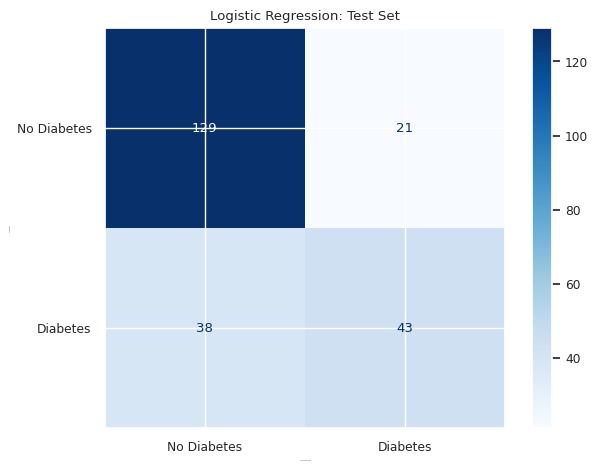

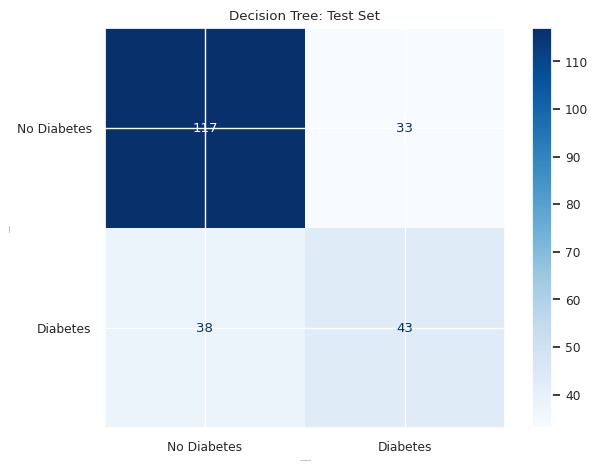

Test-set performance:


,Accuracy,Recall,Precision,F1,ROC AUC
Model,,,,,
Logistic Regression,0.745,0.531,0.672,0.593,0.836
Decision Tree,0.693,0.531,0.566,0.548,0.655


In [491]:
# @title Step 41: Automated Machine Learning Pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Define the models to run automatically in dictionary
models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear", # Algorithm used to optimize the model
        random_state=42     # Ensures reproducibility
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

trained_pipelines = {} # Empty dictionary to store trained models
results = []           # Emppy list to store each model's performance metric
                       # (Accuracy, Recall, Precison, F1 and ROC AUC)

for model_name, classifier in models.items(): # call pair of key/value from dictionary

    # Preprocessing is fitted using training data only.
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    # Apply scaling when appropriate for the model.
    if isinstance(classifier, LogisticRegression):
        steps.append(("scaler", StandardScaler()))

    steps.append(("classifier", classifier))

    pipeline = Pipeline(steps)
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    positive_index = list(pipeline.classes_).index(1)
    probabilities = pipeline.predict_proba(X_test)[:, positive_index]

    trained_pipelines[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["No Diabetes", "Diabetes"],
        cmap="Blues"
    )
    plt.title(f"{model_name}: Test Set")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).set_index("Model")

print("Test-set performance:")
display(results_df.round(3))

Step 41: Automated Machine Learning Pipeline

Two classification models, Logistic Regression and Decision Tree, were defined in a dictionary and processed automatically using a for loop. Empty dictionaries and lists were created to store the trained pipelines and model performance metrics. Median imputation was applied to both models, while standardization was conditionally applied only to Logistic Regression using isinstance(). Each model was trained on the training dataset and evaluated on the test dataset using accuracy, recall, precision, F1 score, and ROC AUC. Confusion matrices were generated for both models, and the results were organized into a DataFrame for comparison. This workflow demonstrates how loops, conditional statements, and pipelines can automate model training and evaluation while applying model-specific preprocessing.

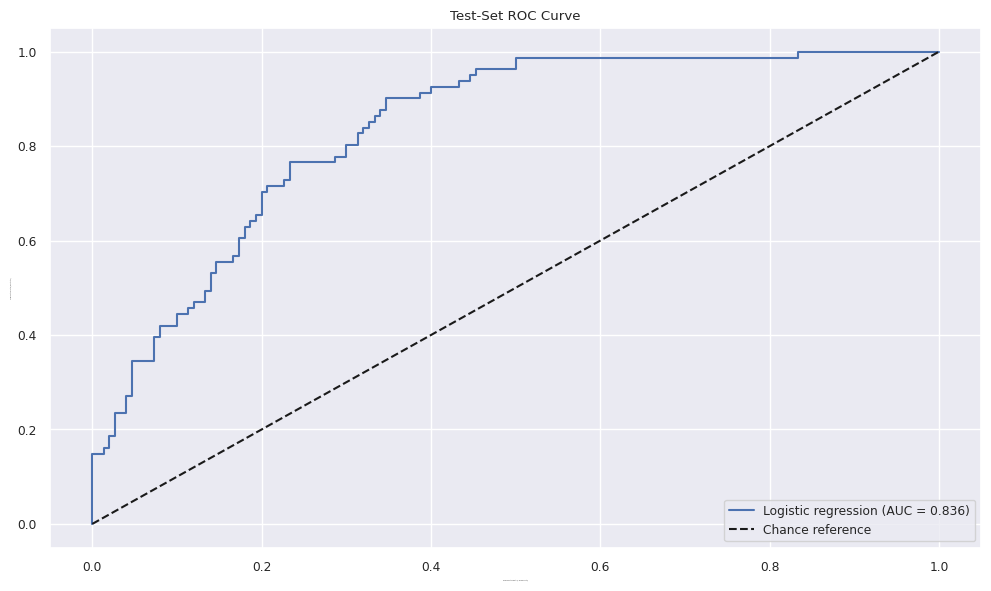

Test-set ROC AUC: 0.836


In [492]:
# @title Step 42: ROC curve and AUC for logistic regression

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Predict probabilities for the positive class (1).
positive_index = list(logistic_pipeline.classes_).index(1)
y_probability = logistic_pipeline.predict_proba(X_test)[:, positive_index]

# Calculate test-set ROC AUC and curve.
logit_roc_auc = roc_auc_score(y_test, y_probability)
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {logit_roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance reference")
plt.xlabel("False Positive Rate (1 − Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Test-Set ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Test-set ROC AUC: {logit_roc_auc:.3f}")

Step 42: ROC Curve and AUC Interpretation

The logistic regression model achieved a test-set ROC AUC of 0.836, indicating good discrimination between diabetic and non-diabetic patients. The ROC curve remained above the diagonal reference line, demonstrating better performance than random classification. While the model achieved an accuracy of 74.46% at the default classification threshold, the ROC AUC evaluates discrimination across multiple thresholds. These findings suggest that the model has good discriminatory ability, although further evaluation of sensitivity, specificity, and calibration is needed to assess its clinical usefulness.

In [493]:
# @title Step 43: Select a cutoff using training-set cross-validation

import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Use the logistic_pipeline defined in the training block.
cv = StratifiedKFold(             # Maintains approximately the same class distribution of the outcome variable across each fold.
    n_splits=5,                   # Divids the dataset into 5 folds
    shuffle=True,                 # Randomly shffles the data before splitting it into folds
    random_state=42               # Ensures reproducibility by generating the same data splits each time the code is executed
)

if y_train.value_counts().min() < 5:
    raise ValueError("Each training class needs at least 5 observations.")

# Each observation is predicted by a pipeline trained on other folds.
# Imputation and scaling are learned separately within each fold.
cv_probabilities = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)

positive_index = list(logistic_pipeline.classes_).index(1)

fpr, tpr, thresholds = roc_curve(
    y_train,
    cv_probabilities[:, positive_index]
)

# Exclude the infinite threshold representing no positive predictions.
finite = np.isfinite(thresholds)
j_scores = tpr[finite] - fpr[finite]
optimal_idx = np.argmax(j_scores)
optimal_threshold = thresholds[finite][optimal_idx]

print(f"Selected threshold: {optimal_threshold:.3f}")
print("Criterion: maximum cross-validation sensitivity + specificity − 1.")
print("Apply this cutoff to the fitted pipeline's test-set probabilities.")

Selected threshold: 0.443
Criterion: maximum cross-validation sensitivity + specificity − 1.
Apply this cutoff to the fitted pipeline's test-set probabilities.


Step 43: Optimal Classification Threshold Using Cross-Validation

Five-fold stratified cross-validation was performed on the training dataset to select an optimal classification threshold for logistic regression. Stratification preserved approximately the same proportion of diabetic and non-diabetic patients across folds. Out-of-fold predicted probabilities were generated using cross_val_predict(), with imputation and scaling performed separately within each training fold to reduce data leakage.

The optimal threshold was selected by maximizing Youden's J statistic (Sensitivity + Specificity − 1), equivalent to maximizing the difference between the true positive rate and false positive rate.

The selected classification threshold was 0.443, compared with the default threshold of 0.500. This lower cutoff may increase sensitivity by identifying more patients with diabetes, although it may also increase false positives. The selected threshold will be applied to the test-set predicted probabilities to evaluate its performance on unseen data.

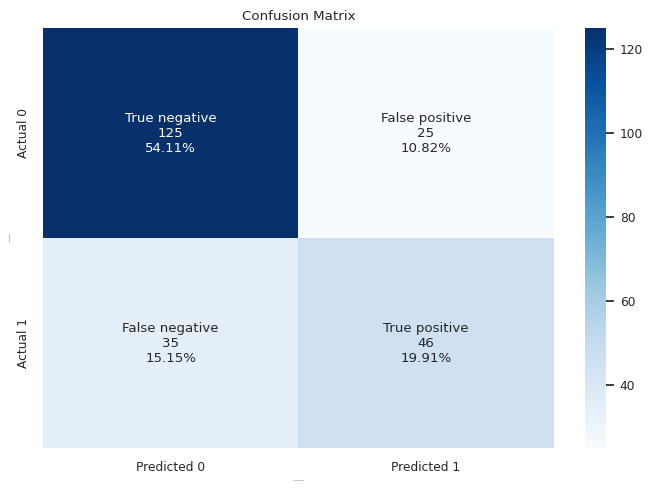

In [494]:
# @title Step 44: Confusion Matrix Using the Selected Threshold

positive_index = list(logistic_pipeline.classes_).index(1)

test_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, positive_index]

y_pred_ts = (test_probabilities >= optimal_threshold).astype(int)

make_confusion_matrix(y_test, y_pred_ts)

Step 44: Confusion Matrix Using the Selected Threshold

The optimal classification threshold of 0.443, selected through training-set cross-validation, was applied to the logistic regression model's test-set predicted probabilities. The resulting confusion matrix showed 125 true negatives, 25 false positives, 35 false negatives, and 46 true positives.

The model achieved an accuracy of 74.03%, sensitivity of 56.79%, specificity of 83.33%, and precision of 64.79%. Although the model correctly classified most observations, it failed to identify 35 of the 81 patients with diabetes. This suggests that sensitivity remains a limitation and should be considered when evaluating the model for potential clinical screening applications.

In [495]:
# @title Step 45: Compare training and test F1 at the selected cutoff

from sklearn.metrics import f1_score

positive_index = list(logistic_pipeline.classes_).index(1)

train_probabilities = logistic_pipeline.predict_proba(
    X_train
)[:, positive_index]

test_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, positive_index]

y_pred_tr = (train_probabilities >= optimal_threshold).astype(int)
y_pred_ts = (test_probabilities >= optimal_threshold).astype(int)

print(f"Selected cutoff: {optimal_threshold:.3f}")
print(f"Training F1: {f1_score(y_train, y_pred_tr, zero_division=0):.3f}")
print(f"Test F1: {f1_score(y_test, y_pred_ts, zero_division=0):.3f}")

Selected cutoff: 0.443
Training F1: 0.669
Test F1: 0.605


The selected classification threshold of 0.443 was applied to both the training and test datasets to compare F1 scores. The training F1 score was 0.669, while the test F1 score was 0.605, representing a difference of 0.064. The lower test F1 score indicates slightly reduced performance on unseen data, suggesting a possible generalization gap. However, this difference alone does not establish overfitting. Overall, the model demonstrated moderate performance in balancing precision and recall.

## **Decision Tree**

**DECISION TREE: https://scikit-learn.org/stable/modules/tree.html#**

In [496]:
# @title Step 46: Import Libraries for Decision Tree Analysis

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Decision tree libraries imported successfully.")

Decision tree libraries imported successfully.


Step 46: Import Libraries for Decision Tree Analysis

The required libraries were imported to support Decision Tree model training, preprocessing, hyperparameter tuning, and performance evaluation. GridSearchCV and StratifiedKFold will be used for cross-validation and model optimization, while classification metrics and visualization tools will help evaluate and interpret model performance. All libraries were imported successfully.

In [497]:
# @title Step 47: Build and tune decision tree using cross-validation F1

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Choose the metric used for tuning.
scoring_metric = "f1"  # Alternatives: "recall", "precision", "accuracy"

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

dtree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Pipeline parameters require the step name prefix.
parameters = {
    "classifier__max_depth": [2, 4, 6, 8],
    "classifier__min_samples_leaf": [5, 10, 15],
    "classifier__max_leaf_nodes": [5, 10, 15],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

if y_train.value_counts().min() < 5:
    raise ValueError("Each training class needs at least 5 observations.")

grid_obj = GridSearchCV(
    estimator=dtree_pipeline,
    param_grid=parameters,
    scoring=scoring_metric,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_obj.fit(X_train, y_train)

# Already refitted on the full training set; no additional fit is needed.
dtree = grid_obj.best_estimator_

print("Decision tree pipeline built and tuned.")
print(f"Best mean cross-validation {scoring_metric}: {grid_obj.best_score_:.3f}")
print("Selected parameters:")
print(grid_obj.best_params_)

Decision tree pipeline built and tuned.
Best mean cross-validation f1: 0.682
Selected parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 8, 'classifier__max_leaf_nodes': 10, 'classifier__min_samples_leaf': 5}


Step 47: Build and tune decision tree using cross-validation F1

A Decision Tree classifier was optimized using GridSearchCV with five-fold stratified cross-validation. The F1 score was selected as the evaluation metric to balance precision and recall. A total of 72 hyperparameter combinations were evaluated, including maximum tree depth, minimum samples per leaf, maximum leaf nodes, and class weights.

The best model achieved a mean cross-validation F1 score of 0.682. The selected parameters were max_depth=8, min_samples_leaf=5, max_leaf_nodes=10, and class_weight="balanced". The optimized pipeline was refitted on the full training dataset and will be evaluated on the test dataset to assess its generalization performance.

In [498]:
# @title Step 48: Function to calculate accuracy, recall, precision, and F1

from sklearn import metrics

def get_metrics_score(model, flag=True):
    """Evaluate a fitted classifier on the existing training and test sets."""

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_acc = metrics.accuracy_score(y_train, pred_train)
    test_acc = metrics.accuracy_score(y_test, pred_test)

    train_recall = metrics.recall_score(
        y_train, pred_train, zero_division=0
    )
    test_recall = metrics.recall_score(
        y_test, pred_test, zero_division=0
    )

    train_precision = metrics.precision_score(
        y_train, pred_train, zero_division=0
    )
    test_precision = metrics.precision_score(
        y_test, pred_test, zero_division=0
    )

    train_f1 = metrics.f1_score(y_train, pred_train, zero_division=0)
    test_f1 = metrics.f1_score(y_test, pred_test, zero_division=0)

    score_list = [
        train_acc, test_acc,
        train_recall, test_recall,
        train_precision, test_precision,
        train_f1, test_f1
    ]

    if flag:
        print(f"{'Metric':<12} {'Training':>10} {'Test':>10}")
        for name, train_value, test_value in [
            ("Accuracy", train_acc, test_acc),
            ("Recall", train_recall, test_recall),
            ("Precision", train_precision, test_precision),
            ("F1", train_f1, test_f1)
        ]:
            print(f"{name:<12} {train_value:>10.3f} {test_value:>10.3f}")

    return score_list

print("Metric evaluation function successfully defined.")

Metric evaluation function successfully defined.


Step 48: Function to calculate accuracy, recall, precision, and F1

A reusable function, get_metrics_score(), was defined to evaluate classification model performance on both training and test datasets. The function calculates accuracy, recall, precision, and F1 score to assess overall classification accuracy and the ability to identify patients with diabetes.

The function uses conditional logic (if flag) to display the results in a formatted comparison table when requested. It also returns a list of eight performance scores for further analysis. Comparing training and test metrics will help assess model generalization and identify potential overfitting.

The function was successfully defined and is ready to evaluate the trained Decision Tree model.

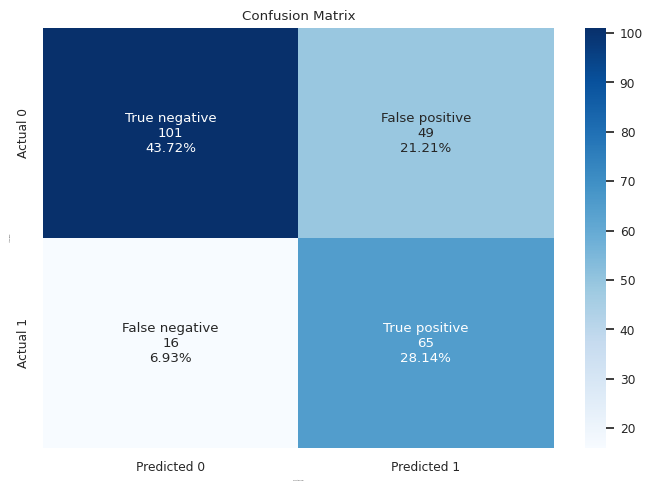

In [499]:
# @title Step 49: Display confusion matrix for the tuned decision tree

y_pred_tree = dtree.predict(X_test)

make_confusion_matrix(y_test, y_pred_tree)

Step 49: Display confusion matrix for the tuned decision tree

The tuned Decision Tree model was evaluated on the test dataset (n = 231). The confusion matrix showed 101 true negatives, 49 false positives, 16 false negatives, and 65 true positives.

The model achieved an accuracy of 71.86%, sensitivity of 80.25%, precision of 57.02%, and specificity of 67.33%. Compared with the logistic regression model using the selected threshold of 0.443, the Decision Tree identified more patients with diabetes (65 versus 46 true positives) and reduced false negatives from 35 to 16. However, it also produced more false positives (49 versus 25).

These findings suggest that the tuned Decision Tree may be more useful for prioritizing sensitivity in diabetes screening, although the increase in false positives should be considered.

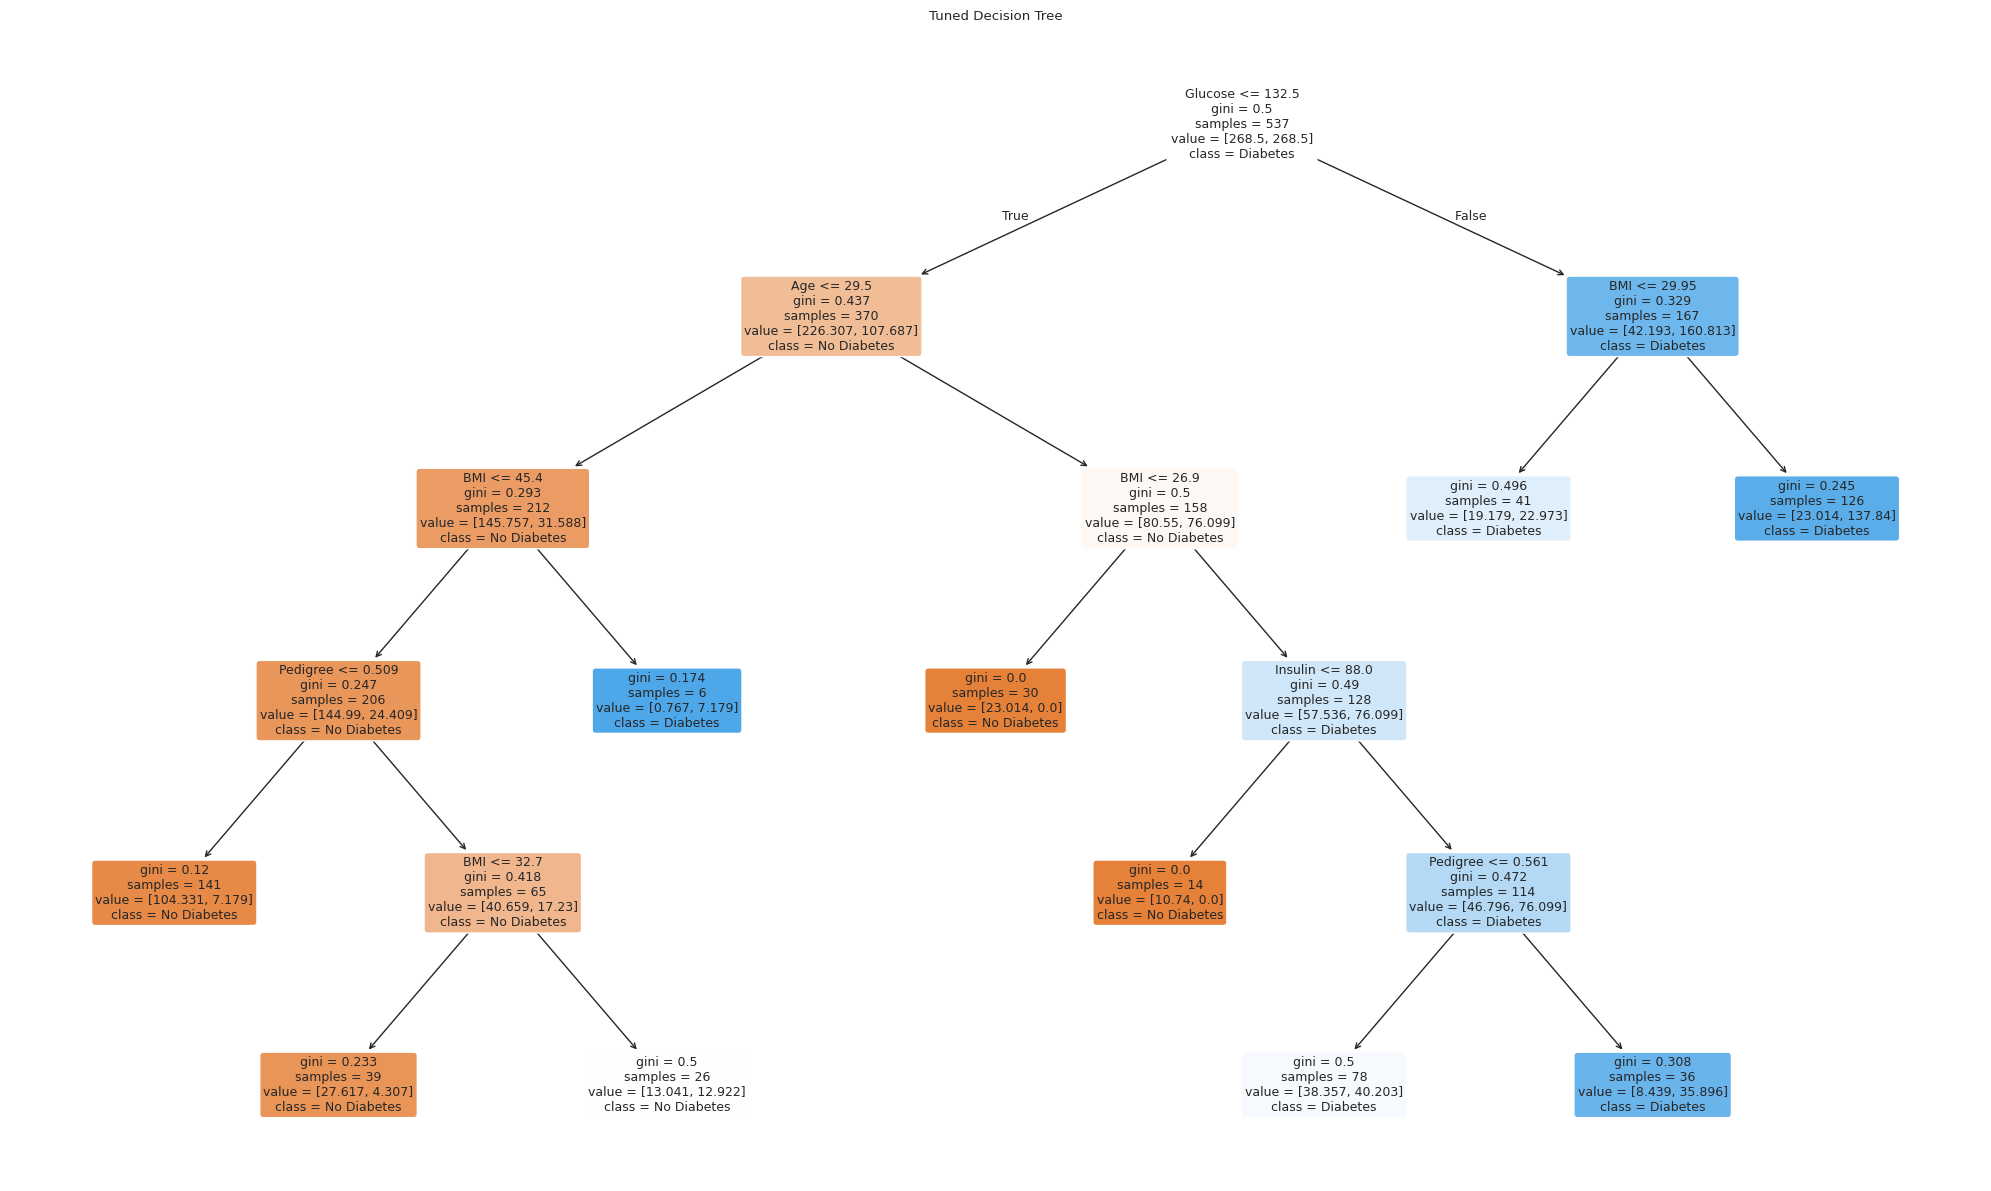

In [500]:
# @title Step 50: Show the tuned decision tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()

plt.figure(figsize=(20, 12))

plot_tree(
    tree_classifier,
    feature_names=list(feature_names),
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=9,
    node_ids=False
)

plt.title("Tuned Decision Tree")
plt.tight_layout()
plt.show()

Step 50: Show the tuned decision tree

The tuned Decision Tree was visualized to examine how predictor variables were used to classify patients with and without diabetes. Glucose was selected as the first splitting variable, with a cutoff of 132.5. Patients with glucose values at or below this threshold were further classified using variables such as age and BMI, while patients with higher glucose values were further evaluated using BMI.

Each node displays the splitting condition, Gini impurity, number of observations, weighted class values, and predicted outcome. Orange nodes represent No Diabetes, while blue nodes represent Diabetes. The visualization demonstrates how the model uses sequential decision rules to classify patients and provides an interpretable representation of the classification process.

In [501]:
# @title Step 51: List feature importance from the tuned decision tree

import pandas as pd

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.reset_index(drop=True).round(3))

,Feature,Importance
0,Glucose,0.464
1,BMI,0.265
2,Age,0.131
3,Pedigree,0.076
4,Insulin,0.063
5,Skin_Thickness,0.000
6,Pregnancies,0.000
7,D_BP,0.000


Step 51: List feature importance from the tuned decision tree

Feature importance was calculated to identify which predictors contributed most to the tuned Decision Tree's classification decisions. Glucose had the highest importance (0.464), followed by BMI (0.265) and Age (0.131). Together, these three variables accounted for approximately 86% of the model's total feature importance.

Pedigree (0.076) and Insulin (0.063) contributed less, while Skin Thickness, Pregnancies, and Diastolic Blood Pressure had importance scores of zero, indicating that they were not used for splitting in the fitted tree.

These findings suggest that Glucose, BMI, and Age were the primary predictors used by this Decision Tree model. However, feature importance reflects the model's internal decision-making process and does not establish causation or clinical significance.

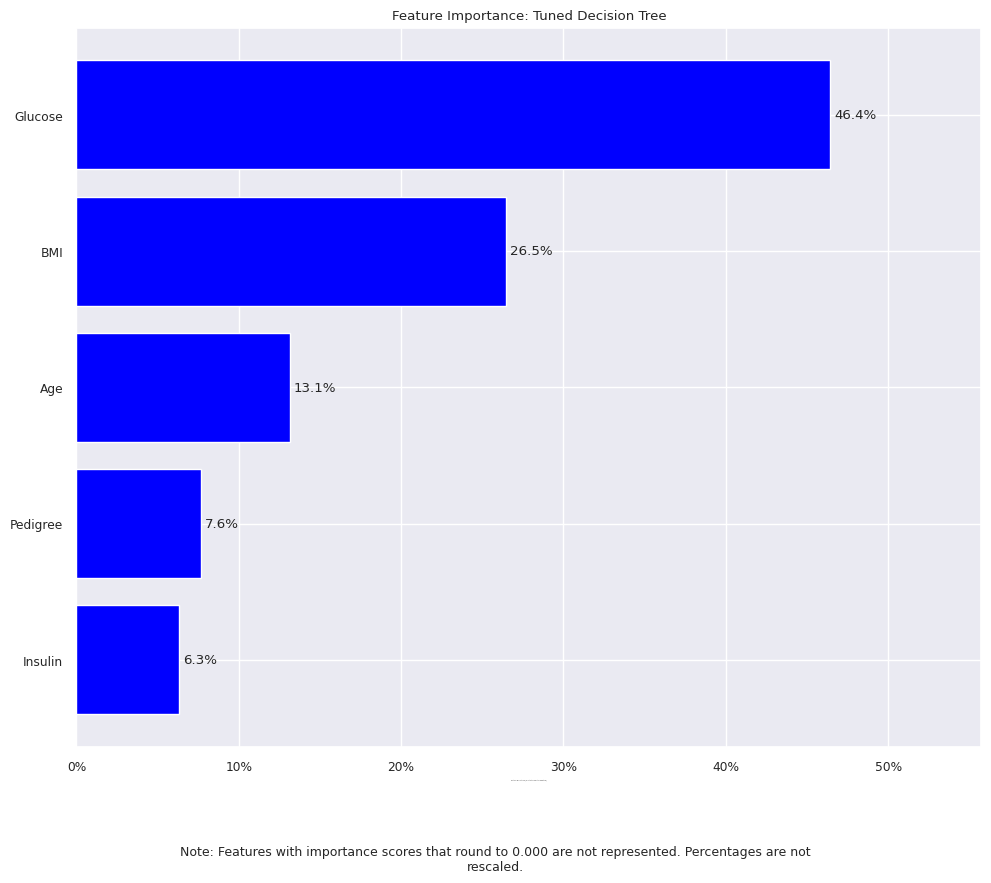

Highest-ranked features in this fitted tree:
- Glucose: 46.4%
- BMI: 26.5%
- Age: 13.1%

Excluded features (importance rounds to 0.000): Pregnancies, D_BP, Skin_Thickness

These percentages describe each feature's share of total impurity reduction, not its effect on diabetes risk.


In [502]:
# @title Step 52: Visualize feature importance from the tuned decision tree

import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import PercentFormatter

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()
importances = tree_classifier.feature_importances_

# Exclude scores that round to 0.000 at three decimal places.
included = np.round(importances, 3) > 0
excluded_features = feature_names[~included].tolist()

excluded_note = (
    "Excluded features (importance rounds to 0.000): "
    + ", ".join(excluded_features)
    if excluded_features
    else "No features were excluded."
)

if included.any():
    shown_names = feature_names[included]
    shown_importances = importances[included]
    indices = np.argsort(shown_importances)

    note = textwrap.fill(
        "Note: Features with importance scores that round to 0.000 "
        "are not represented. Percentages are not rescaled.",
        width=100
    )
    note_lines = len(note.splitlines())
    bottom_margin = 0.6 + 0.18 * note_lines
    figure_height = 8 + bottom_margin

    fig, ax = plt.subplots(figsize=(10, figure_height))

    bars = ax.barh(
        range(len(indices)),
        shown_importances[indices],
        color="blue"
    )

    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(shown_names[indices])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

    ax.bar_label(
        bars,
        labels=[f"{value:.1%}" for value in shown_importances[indices]],
        padding=3
    )

    ax.set_xlim(0, shown_importances.max() * 1.2)
    ax.set_xlabel("Feature Importance (% of total impurity reduction)")
    ax.set_title("Feature Importance: Tuned Decision Tree")

    fig.text(
        0.5, 0.02,
        note,
        ha="center",
        va="bottom",
        fontsize=9
    )

    plt.tight_layout(
        rect=[0, bottom_margin / figure_height, 1, 1]
    )
    plt.show()

    print("Highest-ranked features in this fitted tree:")
    for index in indices[::-1][:3]:
        print(f"- {shown_names[index]}: {shown_importances[index]:.1%}")

else:
    print("All feature importance scores round to 0.000; no graph displayed.")

print(f"\n{excluded_note}")
print(
    "\nThese percentages describe each feature's share of total "
    "impurity reduction, not its effect on diabetes risk."
)

Step 52: Visualize feature importance from the tuned decision tree

A horizontal bar chart was generated to visualize the relative importance of predictors in the tuned Decision Tree model. Glucose showed the highest importance (46.4%), followed by BMI (26.5%) and Age (13.1%). Together, these three variables accounted for approximately 86.0% of the total feature importance.

Features with importance scores rounding to 0.000, including Pregnancies, Diastolic Blood Pressure, and Skin Thickness, were excluded from the visualization to improve readability. Conditional logic was used to determine whether any features met the display criteria.

These percentages represent each feature's relative contribution to reducing impurity within the fitted Decision Tree, rather than its direct effect on diabetes risk. The visualization highlights the predictors most frequently contributing to the model's classification decisions.